# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: Say No Numpy

- Ibi Lilaj Gal
- Gaspar Elizabe
- Miguel Avendaño
- Ángeles Vera

### Ejercicio 1 - DLT ecuaciones formales

#### a.
Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Arrancamos dilucidando cómo se construye la matriz $Q$. Para esto primero analizamos la **correspondencia genérica de los puntos 3D-2D**, la cual está determinada mediante:

$$\lambda_i \begin{pmatrix} u_i \\ v_i \\ 1 \end{pmatrix} = M \begin{pmatrix} U_i \\ V_i \\ W_i \\ 1 \end{pmatrix} = K [R \mid t] \begin{pmatrix} U_i \\ V_i \\ W_i \\ 1 \end{pmatrix}$$

En este sistema:
- $\lambda_i \in \mathbb{R}$ es un factor de escala no nulo.
- $K \in \mathbb{R}^{3 \times 3}$ contiene los parámetros intrínsecos.
- $[R \mid t] \in \mathbb{R}^{3 \times 4}$ representa los parámetros extrínsecos.
- $M = K [R \mid t] \in \mathbb{R}^{3 \times 4}$ es la matriz de proyección homogénea.

Definiendo $\widetilde{P}_i = (U_i, V_i, W_i, 1)^T$ como las coordenadas homogéneas del punto 3D, expresamos $M$ a través de sus tres filas $m_1^T, m_2^T, m_3^T \in \mathbb{R}^{1 \times 4}$:

$$M = \begin{pmatrix} m_1^T \\ m_2^T \\ m_3^T \end{pmatrix} = \begin{pmatrix} m_{11} & m_{12} & m_{13} & m_{14} \\ m_{21} & m_{22} & m_{23} & m_{24} \\ m_{31} & m_{32} & m_{33} & m_{34} \end{pmatrix}$$

La ecuación de proyección para el $i$-ésimo punto se reescribe como:

$$\begin{pmatrix} \lambda_i u_i \\ \lambda_i v_i \\ \lambda_i \end{pmatrix} = \begin{pmatrix} m_1^T \widetilde{P}_i \\ m_2^T \widetilde{P}_i \\ m_3^T \widetilde{P}_i \end{pmatrix}$$

Despejando $\lambda_i = m_3^T \widetilde{P}_i$ e igualando en las dos primeras componentes, obtenemos:

$$\begin{aligned}
    u_i &= \frac{m_1^T \widetilde{P}_i}{m_3^T \widetilde{P}_i} \implies m_1^T \widetilde{P}_i - u_i (m_3^T \widetilde{P}_i) = 0\\
    v_i &= \frac{m_2^T \widetilde{P}_i}{m_3^T \widetilde{P}_i} \implies m_2^T \widetilde{P}_i - v_i (m_3^T \widetilde{P}_i) = 0
\end{aligned}$$

Apilando las dos restricciones para los $n$ puntos de control, obtenemos el **sistema lineal homogéneo global**:

$$Q_{(2n \times 12)} \, m_{(12 \times 1)} = 0_{(2n \times 1)}$$

donde la matriz $Q \in \mathbb{R}^{2n \times 12}$ tiene la siguiente estructura:

$$Q = \begin{pmatrix} 
U_1 & V_1 & W_1 & 1 & 0 & 0 & 0 & 0 & -u_1 U_1 & -u_1 V_1 & -u_1 W_1 & -u_1 \\ 
0 & 0 & 0 & 0 & U_1 & V_1 & W_1 & 1 & -v_1 U_1 & -v_1 V_1 & -v_1 W_1 & -v_1 \\ 
U_2 & V_2 & W_2 & 1 & 0 & 0 & 0 & 0 & -u_2 U_2 & -u_2 V_2 & -u_2 W_2 & -u_2 \\ 
0 & 0 & 0 & 0 & U_2 & V_2 & W_2 & 1 & -v_2 U_2 & -v_2 V_2 & -v_2 W_2 & -v_2 \\ 
\vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots \\ 
U_n & V_n & W_n & 1 & 0 & 0 & 0 & 0 & -u_n U_n & -u_n V_n & -u_n W_n & -u_n \\ 
0 & 0 & 0 & 0 & U_n & V_n & W_n & 1 & -v_n U_n & -v_n V_n & -v_n W_n & -v_n 
\end{pmatrix}$$

Como queremos resolver el sistema homogéneo $Q m = 0$ y la matriz $M$ está definida salvo una escala no nula ($M \sim \alpha M$), buscamos que la solución no nula sea **única a menos de un factor de escala**. Esto requiere que el espacio de soluciones o núcleo de $Q$ tenga dimensión 1 ($\dim(\ker(Q)) = 1$).

Aplicando el **Teorema de la Dimensión (Rango-Nulidad)** sobre la transformación lineal representada por $Q \in \mathbb{R}^{2n \times 12}$:

$$\text{rg}(Q) = \text{columnas}(Q) - \dim(\ker(Q)) = 12 - 1 = 11$$

Por otra parte, dado que cada punto de control $P_i$ aporta 2 filas independientes a la matriz $Q$, la cantidad de filas generadas por $n$ puntos es $2n$. Para asegurar un rango algebraico de 11:

$$2n \geq 11 \implies n \geq 5.5 \implies n \geq 6 \text{ puntos como mínimo}$$

**Condición geométrica de los puntos:**

Para garantizar que las filas generadas por los puntos sean linealmente independientes y alcanzar $\text{rg}(Q) = 11$, los puntos $P_i$ **no deben ser todos coplanares**. 

Si todos los puntos pertenecieran a un mismo plano (por ejemplo, alineando el plano de referencia en $W_i = 0$), las columnas 3, 7 y 11 de la matriz $Q$ se anularían por completo. Esto colapsaría el rango de la matriz a $\text{rg}(Q) = 8$, dando una nulidad de $\dim(\ker(Q)) = 12 - 8 = 4$. En consecuencia, se perdería la unicidad de la solución a menos de una escala (pasando a resolver una homografía 2D en lugar de una calibración 3D).

#### b.
Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

Para evitar la solución trivial $m=0$, se reemplaza la igualdad por un problema de **Mínimos cuadrados homogéneos con restricción de norma unitaria**:

$$\min_{\|m\|_2 = 1} \|Q m\|_2^2$$

Desarrollando la norma euclidea al cuadrado, tenemos que:

$$\|Q m\|_2^2 = (Q m)^t (Q m) = m^t (Q^t Q) m$$

Por lo tanto, con la restricción obtenemos:

$$\min_{\|m\|_2 = 1} m^t (Q^t Q) m$$

Como $Q^tQ\in\mathbb R^{12\times12}$ es una matriz simétrica (pues $(Q^tQ)^t=Q^tQ$) y semidefinida positiva ($m^tQ^tQm=\|Qm\|_2^2\geq0$), podemos desarrollar lo siguiente a partir de la restricción con un vector unitario. La forma cuadrátrica $m^t (Q^t Q) m$ coincide con el cociente de Rayleigh $r(m) = \frac{m^t (Q^t Q) m}{m^t m}$ para $m^tm=\|m\|_2=1$. Por el Teorema Espectral, el minimo de la forma cuadrática sobre la esfera unitaria coincide exactamente con el mínimo autovalor de $Q^t Q$.

$$\min_{\|m\|_2 = 1} m^t (Q^t Q) m = \lambda_{\min}(Q^t Q) = \lambda_{12}(Q^t Q)$$

Y el vector $m$ que resuelve la minimización es el **autovector correspondiente a dicho autovalor mínimo** $\lambda_{12}$.

Por último, mediante la Equivalencia con la SVD reducida de $Q_{24 \times 12} = \hat{U}_{24 \times 12} \, \hat{\Sigma}_{12 \times 12} \, \hat{V}_{12 \times 12}^t$:
$$Q^t Q = (\hat{U} \hat{\Sigma} \hat{V}^t)^t (\hat{U} \hat{\Sigma} \hat{V}^t) = \hat{V} \hat{\Sigma}^t \hat{U}^t \hat{U} \hat{\Sigma} \hat{V}^t = \hat{V} \hat{\Sigma}^2 \hat{V}^t$$

Los autovalores de $Q^t Q$ son los cuadrados de los valores singulares $\lambda_j(Q^t Q) = \sigma_j^2(Q)$, y los autovectores de $Q^t Q$ son las columnas de la matriz ortogonal $\hat{V} = (v_1 \mid v_2 \mid \dots \mid v_{12})$.

Por lo tanto, el vector $m$ que resuelve la minimización $\|Qm\|_2$ con la restricción unitaria, es la última columna de la matriz $\hat{V}(v_{12})$, correspondiente al menor valor singular $\sigma_{12}(Q)$.

### Ejercicio 2 - Calibración con puntos 3D

Utilizando los datos de la carpeta $\texttt{calib/3d}$ 

a) Implementar la función obtenerQ3d(imgPts, objPts) que devuelve la matriz Q a partir
de la ecuación 6.

In [1]:
import numpy as np

def obtenerQ3d(imgPts, objPts):
    """
    Construye la matriz Q de dimensión 2n x 12 para el sistema homogéneo Qm = 0.
    
    Parámetros:
        imgPts: array de n x 2 con coordenadas proyectadas (u, v) en la imagen.
        objPts: array de n x 3 con coordenadas reales (U, V, W) en el espacio 3D.
    Retorna:
        Q: matriz de 2n x 12 con las restricciones apiladas.
    """
    n = objPts.shape[0]
    Q = np.zeros((2 * n, 12))
    
    for i in range(n):
        U, V, W = objPts[i, 0], objPts[i, 1], objPts[i, 2]
        u, v = imgPts[i, 0], imgPts[i, 1]
        
        # Armo las coordenadas homogéneas del punto 3D
        P_i = np.array([U, V, W, 1.0])
        
        # Armo la fila 2i correspondiente a la restricción en la coordenada u
        Q[2 * i, 0:4] = P_i
        Q[2 * i, 4:8] = 0.0
        Q[2 * i, 8:12] = -u * P_i
        
        # Armo la fila 2i + 1 correspondiente a la restricción en la coordenada v
        Q[2 * i + 1, 0:4] = 0.0
        Q[2 * i + 1, 4:8] = P_i
        Q[2 * i + 1, 8:12] = -v * P_i
        
    return Q

b) A partir de lo resuelto en el Ejercicio 1 b), implementar la función resolverDLT3D(Q),
que a partir de Q encuentra la matriz de proyección M.

In [2]:
from alc import arroba, diagRH
# EJERCICIO 2.b
def resolverDLT3D(Q):
    """
    Resuelvo el sistema DLT 3D buscando el vector m que minimiza ||Qm||^2 sujeto a ||m|| = 1.
    Diagonalizo Q^T * Q usando diagRH de alc y extraigo el autovector del menor autovalor.
    """
    # Calculo la matriz simétrica Q^T * Q de 12x12
    QtQ = arroba(Q.T, Q)
    
    # Diagonalizo QtQ mediante el Método de la Potencia y reflectores de Householder
    S, D = diagRH(QtQ, tol=1e-15, K=10000)
    
    # Busco el índice del autovalor de menor valor absoluto
    idx_min = 0
    min_val = abs(D[0, 0])
    for i in range(1, 12):
        val_abs = abs(D[i, i])
        if val_abs < min_val:
            min_val = val_abs
            idx_min = i
            
    # Extraigo el autovector m asociado y lo normalizo en norma 2
    m = S[:, idx_min]
    norma_m = np.sqrt(np.sum(m**2))
    m = m / norma_m
    
    # Reorganizo el vector m de 12 elementos en la matriz de proyección M de 3x4
    M = m.reshape((3, 4))
    return M


c) Una vez recuperada M, se la descompone en la matriz de parámetros intrínsecos K,
la matriz de rotación R y el vector de traslación t, imponiendo que R sea ortonormal
(RRT = I). Para ello, implementar la función devolverMatricesCalibracion3d(M),
que devuelva R, t y K.

d) Agregar a la función devolverMatricesCalibracion3d un parámetro opcional que permita imponer que αu = αv y/o K12 = 0.

In [3]:
from alc import QR_con_HH
# EJERCICIOS 2.c y 2.d: DESCOMPOSICIÓN DE M EN K, R Y t
def descomposicion_RQ_3x3(A):
    """
    Realizo la descomposición RQ de una matriz A de 3x3 mediante la factorización QR de alc.
    Descompongo A en K * R, donde K es triangular superior y R es ortogonal.
    """
    # Defino la matriz de permutación/reversión P de 3x3
    P = np.array([[0., 0., 1.],
                  [0., 1., 0.],
                  [1., 0., 0.]])
    
    # Mapeo el problema a una factorización QR mediante (P * A)^T
    PA_T = arroba(P, A).T
    
    # Factorizo utilizando QR_con_HH de alc
    Q_qr, R_qr = QR_con_HH(PA_T)
    
    # Reconstruyo la matriz K (triangular superior) y R (ortogonal)
    K = arroba(P, arroba(R_qr.T, P))
    R = arroba(P, Q_qr.T)
    
    # Ajusto los signos de las columnas de K y filas de R para asegurar diagonal positiva en K
    for i in range(3):
        if K[i, i] < 0:
            K[:, i] = -K[:, i]
            R[i, :] = -R[i, :]
            
    # Calculo el determinante de R para garantizar det(R) = +1 (rotación pura)
    det_R = (R[0, 0] * (R[1, 1] * R[2, 2] - R[1, 2] * R[2, 1]) -
             R[0, 1] * (R[1, 0] * R[2, 2] - R[1, 2] * R[2, 0]) +
             R[0, 2] * (R[1, 0] * R[2, 1] - R[1, 1] * R[2, 0]))
             
    if det_R < 0:
        R = -R
        K = -K
        
    return K, R


def devolverMatricesCalibracion3d(M, fijar_sesgo_cero=False, igualar_focales=False):
    """
    Descompongo la matriz de proyección M (3x4) en las matrices K (intrínsecos), R (rotación)
    y el vector t (traslación).
    Permito opcionalmente imponer la condición de sesgo nulo (gamma = 0)
    y/o igualar las distancias focales (alpha_u = alpha_v).
    """
    # Separo la submatriz A (3x3) y la columna b (3x1) de M = [A | b]
    A = M[:, 0:3]
    b = M[:, 3]
    
    # Descompongo la submatriz A en K y R usando la rutina RQ
    K, R = descomposicion_RQ_3x3(A)
    
    # Normalizo K para asegurar que el elemento homogéneo K[2,2] valga 1
    K = K / K[2, 2]
    
    # Impongo las restricciones opcionales sobre la matriz de intrínsecos K
    if fijar_sesgo_cero:
        K[0, 1] = 0.0  # gamma = 0
        
    if igualar_focales:
        alpha_prom = (K[0, 0] + K[1, 1]) / 2.0
        K[0, 0] = alpha_prom
        K[1, 1] = alpha_prom
        
    # Calculo el vector de traslación t resolviendo K * t = b -> t = K^-1 * b
    # Como K es triangular superior de 3x3, resuelvo por sustitución hacia atrás
    t = np.zeros(3)
    t[2] = b[2] / K[2, 2]
    t[1] = (b[1] - K[1, 2] * t[2]) / K[1, 1]
    t[0] = (b[0] - K[0, 1] * t[1] - K[0, 2] * t[2]) / K[0, 0]
    
    return R, t, K

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

**Rango de $Q$.** La homografía $H$ tiene 9 entradas pero está definida salvo un factor de escala, es decir, tiene 8 grados de libertad. Para que la solución de $Qh=0$ sea única a menos de escala necesitamos $\dim\ker Q=1$, y por el Teorema de la Dimensión
$$\text{rg}(Q)=9-\dim\ker Q = 8 .$$
Cada correspondencia aporta 2 filas independientes a $Q\in\mathbb{R}^{2n\times 9}$, de modo que alcanza con $2n\ge 8$, o sea $n\ge 4$ puntos, **con la condición de que no haya tres colineales** (si los hubiera, las ecuaciones de esos puntos serían linealmente dependientes y el rango bajaría de 8). En nuestro caso hay $n=77$ esquinas por imagen, por lo que el sistema está sobredeterminado y, como en el Ejercicio 1.b, resolvemos $\min_{\|h\|=1}\|Qh\|^2$: $h$ es el autovector de menor autovalor de $Q^tQ$.


In [4]:
import numpy as np
import alc

def obtenerQ2d(imgPts, objPts):
    """
    Arma la matriz Q del sistema homogéneo Qh = 0 (ecuación 11) para estimar
    la homografía H entre puntos coplanares del mundo y puntos de la imagen.

    Parámetros:
        imgPts: matriz de n x 2 con las coordenadas (u_i, v_i) en píxeles.
        objPts: matrix de n x 2 (o n x 3) con las coordenadas (U_i, V_i) del
                plano del objeto (en mm), y W = 0.
                imgPts[i] y objPts[i] deben corresponder al mismo punto físico.

    Retorna:
        Q: array de 2n x 9, donde h = (h11, h12, h13, h21, h22, h23, h31, h32, h33)
           es el vector que debería quedar en el núcleo de Q.
    """
    imgPts = np.array(imgPts)
    objPts = np.array(objPts)

    n = len(objPts)               # cantidad de correspondencias
    Q = np.zeros((2 * n, 9))      # 2 ecuaciones por punto, 9 incógnitas

    for i in range(n):
        U, V = objPts[i, 0], objPts[i, 1]   # punto en el plano del tablero
        u, v = imgPts[i, 0], imgPts[i, 1]   # punto correspondiente en la imagen

        # Fila 2i: ecuación de u  ->  [P^T, 0^T, -u*P^T], con P = (U, V, 1)
        Q[2 * i, 0:3] = [U, V, 1]
        Q[2 * i, 6:9] = [-u * U, -u * V, -u]

        # Fila 2i+1: ecuación de v  ->  [0^T, P^T, -v*P^T]
        Q[2 * i + 1, 3:6] = [U, V, 1]
        Q[2 * i + 1, 6:9] = [-v * U, -v * V, -v]

    return Q


#----------------


def vij(H, i, j):
    """
    Arma el vector v_ij de 6 entradas tal que c_i^T B c_j = v_ij^T b,
    con b = [B11, B12, B22, B13, B23, B33]^T y c_i la i-ésima columna de H.

    Parámetros:
        H: matriz de 3 x 3 (homografía de una vista).
        i, j: índices de columna.

    Retorna:
        v: vector de 6 coordenadas.
    """
    H = np.asarray(H)
    v = np.zeros(6)
    # H[k, i] es la componente k de la columna c_i (h_{i,k+1})
    v[0] = H[0, i] * H[0, j]
    v[1] = H[0, i] * H[1, j] + H[1, i] * H[0, j]
    v[2] = H[1, i] * H[1, j]
    v[3] = H[2, i] * H[0, j] + H[0, i] * H[2, j]
    v[4] = H[2, i] * H[1, j] + H[1, i] * H[2, j]
    v[5] = H[2, i] * H[2, j]
    return v


def armarA(Hlst):
    """
    Arma la matriz A del sistema homogéneo Ab = 0, r1 y r2 ortonormales, donde
    b = [B11, B12, B22, B13, B23, B33]^T y B = K^{-T} K^{-1}.

    Parámetros:
        Hlst: lista de N matrices H_j de 3 x 3, obtenidas
              con el DLT de puntos coplanares.

    Retorna:
        A: matriz de 2N x 6. Cada vista j aporta dos filas:
           fila 2j:   v12^T          (c1^T B c2 = 0, perpendicularidad)
           fila 2j+1: (v11 - v22)^T  (c1^T B c1 = c2^T B c2, igual norma)
    """
    N = len(Hlst)                 # cantidad de vistas
    A = np.zeros((2 * N, 6))      # 2 ecuaciones por vista, 6 incógnitas en b

    for j in range(N):
        H = np.asarray(Hlst[j])
        H = H / H[2, 2]           # normalizo la escala de cada H

        v12 = vij(H, 0, 1)        # c1 con c2
        v11 = vij(H, 0, 0)        # c1 con c1
        v22 = vij(H, 1, 1)        # c2 con c2

        A[2 * j] = v12
        A[2 * j + 1] = v11 - v22

    return A


def vectorMenorSingular(M): #AUX
    """
    Devuelve el vector unitario x que minimiza ||Mx|| con ||x|| = 1.
    Es el autovector de menor autovalor de M^T M (= vector singular derecho
    del menor valor singular de M). Sirve para el DLT (Q h = 0) y para A b = 0.

    Parámetros:
        M: array de m x n.
    Retorna:
        x: array de n, de norma 1.
    """
    MtM = alc.arroba(M.T, M)
    S, D = alc.diagRH(MtM)          # S: autovectores (columnas), D: diagonal de autovalores
    n = MtM.shape[0]

    idx = 0
    for i in range(1, n):
        if D[i, i] < D[idx, idx]: #recorre valores singulares y se queda con el menor
            idx = i

    x = S[:, idx].copy()
    return x / alc.norma(x, 2)


def choleskyPropio(B): #AUX
    """
    Factorización de Cholesky B = L L^T, con L triangular inferior.
    Parámetros: B (n x n) simétrica definida positiva.
    Retorna: L (n x n), o None si B no es definida positiva.
    """
    n = B.shape[0]
    L = np.zeros((n, n))
    for j in range(n):
        suma = 0.0
        for k in range(j):
            suma = suma + L[j, k] * L[j, k]
        d = B[j, j] - suma
        if d <= 0:
            return None                      # B no es definida positiva
        L[j, j] = np.sqrt(d)
        for i in range(j + 1, n):
            suma = 0.0
            for k in range(j):
                suma = suma + L[i, k] * L[j, k]
            L[i, j] = (B[i, j] - suma) / L[j, j]
    return L


def productoCruz(a, b): #AUX
    """Producto vectorial de dos vectores de R^3."""
    c = np.zeros(3)
    c[0] = a[1] * b[2] - a[2] * b[1]
    c[1] = a[2] * b[0] - a[0] * b[2]
    c[2] = a[0] * b[1] - a[1] * b[0]
    return c


def calcularMatrizK2D(A):
    """
    Calcula K a partir de A (2N x 6), donde A b = 0 con
    b = [B11, B12, B22, B13, B23, B33]^T y B = K^{-T} K^{-1}.
    Retorna K (3 x 3, triangular superior, K[2,2] = 1), o None si B no
    resulta definida positiva.
    """
    # Mínimos cuadrados homogéneos
    b = vectorMenorSingular(A)

    # Reconstruir B simétrica
    B = np.array([[b[0], b[1], b[3]],
                  [b[1], b[2], b[4]],
                  [b[3], b[4], b[5]]])

    # Signo: B debe ser definida positiva (diagonal positiva), elige signo tal que lo sea
    if B[0, 0] < 0:
        B = -1.0 * B

    # Cholesky: B = L L^T, L = K^{-T}  =>  K = (L^T)^{-1}
    L = choleskyPropio(B)
    if L is None:
        return None
    K = alc.inversa(L.T)

    # Normalizar K[2,2] = 1
    return K / K[2, 2]


def obtenerPose2D(Hj, K):
    """
    Pose (R, t) de la vista j a partir de su homografía Hj (3x3, ya
    desnormalizada) y de K. t queda en las unidades de objPts (mm).
    """
    Hj = np.asarray(Hj, dtype=float)
    Kinv = alc.inversa(K)

    # K^{-1} c_i  (r_i salvo escala)
    a1 = alc.arroba(Kinv, Hj[:, 0])
    a2 = alc.arroba(Kinv, Hj[:, 1])
    a3 = alc.arroba(Kinv, Hj[:, 2])

    lam = 1.0 / alc.norma(a1, 2)            # ||r1|| = 1
    r1, r2, t = lam * a1, lam * a2, lam * a3

    # Signo: el tablero debe quedar delante de la cámara (t_z > 0)
    if t[2] < 0:
        r1, r2, t = -1.0 * r1, -1.0 * r2, -1.0 * t

    # Tercer eje y matriz con columnas [r1 r2 r3]
    r3 = productoCruz(r1, r2)
    M = np.zeros((3, 3))
    M[:, 0] = r1
    M[:, 1] = r2
    M[:, 2] = r3

    # Ortonormalización con Gram-Schmidt
    R, _ = alc.QR_con_GS(M)
    return R, t


In [5]:
def normalizarPuntos(pts):
    """
    Normalizacion isotropica de Hartley: lleva el centroide al origen y escala para que la
    distancia media al origen sea sqrt(2).
    Parametros: pts, array de n x 2.
    Retorna: (pts_norm de n x 2, T de 3 x 3) con p_norm = T p (en coordenadas homogeneas).
    """
    pts = np.array(pts, dtype=float)
    n = pts.shape[0]
    cx = np.mean(pts[:, 0])
    cy = np.mean(pts[:, 1])
    d = np.sqrt((pts[:, 0] - cx) ** 2 + (pts[:, 1] - cy) ** 2)
    s = np.sqrt(2.0) / np.mean(d)
    T = np.array([[s, 0.0, -s * cx],
                  [0.0, s, -s * cy],
                  [0.0, 0.0, 1.0]])
    pn = np.zeros((n, 2))
    pn[:, 0] = s * (pts[:, 0] - cx)
    pn[:, 1] = s * (pts[:, 1] - cy)
    return pn, T


def estimarHomografia(imgPts, objPts):
    Q = obtenerQ2d(imgPts, objPts)
    h = vectorMenorSingular(Q)
    H = h.reshape(3, 3)
    return H / H[2, 2]

def errorReproyeccion(R, t, K, objPts, imgPts):
    """Error medio (px) de reproyectar los puntos planos objPts (W = 0) con K [R | t]."""
    n = objPts.shape[0]
    suma = 0.0
    for i in range(n):
        P = np.array([objPts[i, 0], objPts[i, 1], 0.0])
        Xc = alc.arroba(R, P) + t
        h = alc.arroba(K, Xc)
        du = h[0] / h[2] - imgPts[i, 0]
        dv = h[1] / h[2] - imgPts[i, 1]
        suma = suma + np.sqrt(du * du + dv * dv)
    return suma / n

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
np.set_printoptions(suppress=True, precision=4)

# objPts: esquinas internas del tablero (11 x 7, cuadrados de 30 mm, W = 0)
objPts = np.zeros((77, 2))
k = 0
for j in range(7):              # 7 filas de esquinas
    for i in range(11):         # 11 esquinas por fila
        objPts[k, 0] = 30.0 * i
        objPts[k, 1] = 30.0 * j
        k = k + 1

# imgPts: esquinas detectadas en cada imagen (20 filas x 154 valores: u0 v0 u1 v1 ...)
carpeta = os.path.join('calib', 'coplanar')
datos = np.loadtxt(os.path.join(carpeta, 'esquinas_coplanar.csv'), delimiter=',')

# a) K: una homografia por vista, luego A, luego K
Hlst = []
for j in range(20):
    imgPts_j = datos[j].reshape(77, 2)
    Hlst.append(estimarHomografia(imgPts_j, objPts))

A = armarA(Hlst)
K = calcularMatrizK2D(armarA(Hlst))
print("A:", A.shape)
print("\nMatriz de parametros intrinsecos K:")
print(K)

FileNotFoundError: calib/coplanar/esquinas_coplanar.csv not found.

In [ ]:
# b) Pose de Im_R_1, Im_R_10 e Im_R_20
poses = {}
for idx in (1, 10, 20):
    imgPts_j = datos[idx - 1].reshape(77, 2)
    R, t = obtenerPose2D(Hlst[idx - 1], K)
    poses[idx] = (R, t)
    print("=== Im_R_%d ===" % idx)
    print("R =");  print(R)
    print("t (mm) =", t)
    print("R R^T - I (max abs):", np.max(np.abs(alc.arroba(R, R.T) - np.eye(3))))
    print("Error de reproyeccion medio: %.3f px\n" % errorReproyeccion(R, t, K, objPts, imgPts_j))

# Reproyeccion de todas las esquinas sobre Im_R_1
R1, t1 = poses[1]
img1 = mpimg.imread(os.path.join(carpeta, 'Im_R_1.png'))
rep = np.zeros((77, 2))
for i in range(77):
    h = alc.arroba(K, alc.arroba(R1, np.array([objPts[i, 0], objPts[i, 1], 0.0])) + t1)
    rep[i, 0] = h[0] / h[2]
    rep[i, 1] = h[1] / h[2]
det1 = datos[0].reshape(77, 2)
plt.figure(figsize=(9, 5))
plt.imshow(img1)
plt.scatter(det1[:, 0], det1[:, 1], s=30, c='lime', label='esquinas detectadas')
plt.scatter(rep[:, 0], rep[:, 1], s=8, c='red', label='reproyeccion con K, R, t')
plt.title('Im_R_1: reproyeccion de las esquinas con la pose estimada')
plt.legend()
plt.tight_layout()
plt.show()

SyntaxError: expected argument value expression (570214379.py, line 1)

**a) Matriz de parámetros intrínsecos.** Con las 20 vistas obtuvimos

$$K\approx\begin{pmatrix}743.2&-1.02&519.6\\0&754.4&298.5\\0&0&1\end{pmatrix}$$

es decir, $\alpha_u\approx743$, $\alpha_v\approx754$, punto principal $(u_0,v_0)\approx(520,299)$ y un sesgo $\gamma\approx-1.0$, prácticamente nulo. Cada homografía reproyecta las 77 esquinas con un error menor a 0,25 px, lo que valida la etapa DLT con normalización de Hartley.

Contrastamos el resultado (solo durante el desarrollo, sin usarlo en el código entregado) con `cv2.calibrateCamera` sin distorsión, que da $f_x\approx717$, $f_y\approx728$ y $(u_0,v_0)\approx(513,292)$. La diferencia, de alrededor del 3–4 %, es esperable: nuestra $K$ es la solución cerrada de Zhang (mínimos cuadrados algebraicos), mientras que OpenCV la refina minimizando el error de reproyección. Además, en estas 20 capturas el tablero casi siempre mira de frente a la cámara (las rotaciones son de unos pocos grados), lo que deja a $K$ relativamente mal condicionada.

**b) Poses** (con $X_{cam}=R\,X+t$, $t$ en mm; el origen del tablero es la esquina interna superior izquierda, con $U$ hacia la derecha y $V$ hacia abajo en la imagen):

| Imagen | $t$ (mm) | error de reproyección (px) |
|---|---|---|
| `Im_R_1` | $(-108.7,\ -141.3,\ 548.8)$ | 0.20 |
| `Im_R_10` | $(-95.9,\ -154.0,\ 539.7)$ | 0.21 |
| `Im_R_20` | $(-83.3,\ -146.3,\ 487.9)$ | 0.21 |

En las tres vistas $R$ resulta ortonormal con $\det R=+1$ y se parece a la identidad, como corresponde a un tablero casi frontal, y $t_z>0$ (el tablero queda delante de la cámara, a unos 49–55 cm). Las tres poses reproyectan las esquinas con error medio de aproximadamente 0,2 px.

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

In [ ]:
import numpy as np
import alc as alc

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg



In [ ]:
def productoCruz(a, b):
    """Producto vectorial de dos vectores de R^3."""
    c = np.zeros(3)
    c[0] = a[1] * b[2] - a[2] * b[1]
    c[1] = a[2] * b[0] - a[0] * b[2]
    c[2] = a[0] * b[1] - a[1] * b[0]
    return c


def calculoLambdaMu(I0, J0):
    """
    Resuelve lambda y mu de la ecuación 16 (C^2 = (lambda + i mu)^2).
    Parámetros: I0, J0 (vectores de R^3), soluciones del paso POS.
    Retorna: (lam, mu) con lam >= 0. La otra solución es (-lam, -mu).
    Se cumple: lam*mu = -I0.J0   y   lam^2 - mu^2 = |J0|^2 - |I0|^2.
    """

    '''Dos restricciones I^T J = 0 y ||I||^2 = ||J||^2.
    lambda ^2 - u^2 = ||J_0||^2 - ||I_0||^2
    C = lambda = i.u ====> C^2 = lamda ^2 - U^2 + 2i lamda U ====> C^2 = ||J_0||^2 - ||I_0||^2 -2i I_0 J_0'''
    I0 = np.array(I0)
    J0 = np.array(J0)
    r = np.sum(J0 * J0) - np.sum(I0 * I0)       # parte real de C^2 = ||J_0||^2 - ||I_0||^2
    i = -2.0 * np.sum(I0 * J0)                  # parte imaginaria de C^2 = -2i I_0 J_0
    rho = np.sqrt(r * r + i * i)             # módulo de C^2
    lam = np.sqrt((rho + r) / 2.0)
    if lam > 1e-12:
        mu = i / (2.0 * lam)
    else:                                         # caso lam = 0: C^2 real y <= 0
        mu = np.sqrt(max((rho - r) / 2.0, 0.0))
    return lam, mu


def calcularSalidaPOSIT(Is, Js, fx, m0, M0):
    """
    Pose asociada a una solución (Is, Js) del paso POS.
    Parámetros:
        Is, Js: vectores I y J (R^3).
        fx: distancia focal en píxeles.
        m0: (x0, y0) imagen de M0 centrada en el punto principal.
        M0: coordenadas de M0 en el sistema del objeto (R^3).
    Retorna: i, j, k, Z0, R, t   (X_cam = R*M + t).
    """
    Is = np.array(Is)
    Js = np.array(Js)
    nI = alc.norma(Is, 2)
    nJ = alc.norma(Js, 2)
    Z0 = fx / nI                                  # = fx / ||J|| si las normas coinciden
    i = Is / nI
    j = Js / nJ
    k = productoCruz(i, j)
    R = np.zeros((3, 3))
    R[0, :] = i
    R[1, :] = j
    R[2, :] = k
    # T = posición de M0 en coordenadas de cámara
    T = np.array([Z0 * m0[0] / fx, Z0 * m0[1] / fx, Z0])
    # X_cam = R (M - M0) + T  =>  t = T - R M0
    t = T - alc.arroba(R, np.asarray(M0))
    return i, j, k, Z0, R, t


def evaluarPose(R, t, obj_vecs, img_vecs, K):
    """
    Cuenta las proyecciones válidas (Z > 0) y calcula el RMS de reproyección
    (en píxeles) sobre los puntos válidos.
    Retorna: (cantidad_validas, rms). Si no hay válidas, rms = inf.
    """
    obj_vecs = np.array(obj_vecs)
    img_vecs = np.array(img_vecs)
    n = obj_vecs.shape[0]
    validas = 0
    suma = 0.0
    for p in range(n):
        Xc = alc.arroba(R, obj_vecs[p]) + t
        if Xc[2] > 0:
            validas = validas + 1
            u = (K[0, 0] * Xc[0] + K[0, 1] * Xc[1]) / Xc[2] + K[0, 2]
            v = K[1, 1] * Xc[1] / Xc[2] + K[1, 2]
            du = u - img_vecs[p, 0]
            dv = v - img_vecs[p, 1]
            suma = suma + du * du + dv * dv
    if validas == 0:
        return 0, np.inf
    return validas, np.sqrt(suma / validas)


def pseudoinversa_rango2(A):
    """Pseudoinversa A^+ = V S^-1 U^T de una matriz de rango 2, y la normal al plano."""
    U, S, V = alc.svd_reducida(A, k=2)
    n_ = V.shape[0]
    Ap = np.zeros((n_, A.shape[0]))
    for c in range(2):
        Ap = Ap + (V[:, c].reshape(n_, 1) * U[:, c].reshape(1, A.shape[0])) / S[c]
    normal = productoCruz(V[:, 0], V[:, 1])
    normal = normal / alc.norma(normal, 2)
    return Ap, normal


def aplicarPOSIT(obj_vecs, img_vecs, K, MaxIt=50, atol=1e-6):
    """
    POSIT coplanar. obj_vecs (n x 3): puntos del objeto; el primero es M0.
    img_vecs (n x 2): píxeles (u, v) de los mismos puntos, mismo orden.
    Retorna (R, t) con X_cam = R*M + t (t en las unidades de obj_vecs), o None.
    """
    obj_vecs = np.asarray(obj_vecs)
    img_vecs = np.asarray(img_vecs)
    n = obj_vecs.shape[0]
    fx = K[0, 0]

    # Coordenadas de imagen centradas; y se reescala por fx/fy para tener una
    # cámara equivalente con una única focal fx
    x = img_vecs[:, 0] - K[0, 2]
    y = (img_vecs[:, 1] - K[1, 2]) * (fx / K[1, 1])
    x0, y0 = x[0], y[0]
    M0 = obj_vecs[0]

    A = obj_vecs[1:] - M0                          # a_i = M0Mi
    Ap, normal = pseudoinversa_rango2(A)

    eps = np.zeros(n - 1)
    rms_ant = np.inf
    mejor = None
    for it in range(MaxIt):
        bu = x[1:] * (1.0 + eps) - x0
        bv = y[1:] * (1.0 + eps) - y0
        I0 = alc.arroba(Ap, bu)
        J0 = alc.arroba(Ap, bv)
        lam, mu = calculoLambdaMu(I0, J0)

        elegida = None
        for signo in (1.0, -1.0):                  # las dos poses simétricas
            Is = I0 + signo * lam * normal
            Js = J0 + signo * mu * normal
            i, j, k, Z0, R, t = calcularSalidaPOSIT(Is, Js, fx, (x0, y0), M0)
            validas, rms = evaluarPose(R, t, obj_vecs, img_vecs, K)
            if validas == n and (elegida is None or rms < elegida[0]):
                elegida = (rms, R, t, k, Z0)
        if elegida is None:
            break                                  # ninguna pose con todos los puntos delante
        rms, R, t, k, Z0 = elegida
        mejor = (R, t)
        eps = alc.arroba(A, k) / Z0                # nuevos factores de corrección
        if abs(rms_ant - rms) < atol:
            break
        rms_ant = rms
    return mejor

Centro de la H en la imagen (px): [ 523.2397 1003.4537]

R =
[[-0.1367 -0.9895  0.0466]
 [-0.9095  0.1067 -0.4019]
 [ 0.3927 -0.0974 -0.9145]]
t (m) = [-0.7088  0.9201  4.5288]

R R^T - I (max abs): 5.551115123125783e-17
Proyecciones validas: 5 de 5,  RMS de reproyeccion: 1.470 px


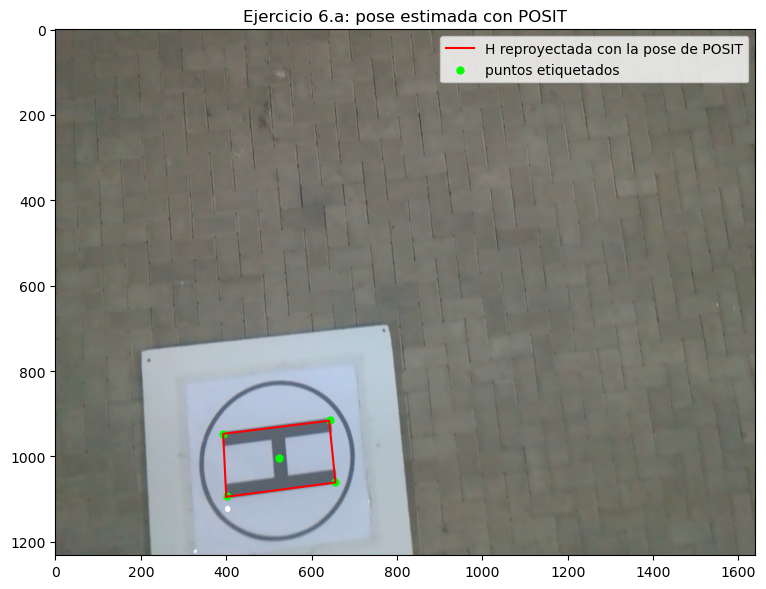

In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
np.set_printoptions(suppress=True, precision=4)

K_dron   = np.loadtxt(os.path.join('template-alumnos-20261026/heli', 'K.csv'), delimiter=';')
obj_vecs = np.loadtxt(os.path.join('template-alumnos-20261026/heli', 'object_points.csv'), delimiter=';',
                      skiprows=1, usecols=(1, 2, 3))          # M0 (centro de la H) + 4 esquinas, en metros
imagen   = mpimg.imread(os.path.join('template-alumnos-20261026/heli', 'row_00248.png'))

# Puntos etiquetados sobre la imagen (px): las 4 esquinas exteriores de la H
# (la H esta girada ~90 grados: el punto blanco queda junto a la esquina "superior izquierda" de la letra)
sup_izq = np.array([402.0, 1093.0])
sup_der = np.array([393.0,  947.0])
inf_der = np.array([643.0,  915.0])
inf_izq = np.array([656.0, 1061.0])

def interseccion(p1, p2, p3, p4):
    """Interseccion de las rectas p1-p2 y p3-p4 (regla de Cramer)."""
    d1 = p2 - p1
    d2 = p4 - p3
    det = d1[0] * (-d2[1]) - (-d2[0]) * d1[1]
    b = p3 - p1
    s = (b[0] * (-d2[1]) - (-d2[0]) * b[1]) / det
    return p1 + s * d1

# El centro de la H (M0) es la imagen de la interseccion de las diagonales del rectangulo
centro = interseccion(sup_izq, inf_der, sup_der, inf_izq)
img_vecs = np.array([centro, sup_izq, sup_der, inf_der, inf_izq])

# a) POSIT
R_dron, t_dron = aplicarPOSIT(obj_vecs, img_vecs, K_dron, MaxIt=50, atol=1e-8)
validas, rms = evaluarPose(R_dron, t_dron, obj_vecs, img_vecs, K_dron)
print("Centro de la H en la imagen (px):", centro)
print("\nR =");  print(R_dron)
print("t (m) =", t_dron)
print("\nR R^T - I (max abs):", np.max(np.abs(alc.arroba(R_dron, R_dron.T) - np.eye(3))))
print("Proyecciones validas: %d de %d,  RMS de reproyeccion: %.3f px" % (validas, len(obj_vecs), rms))

def proyectar(R, t, K, P):
    """Proyecta puntos P (n x 3, sistema del objeto) a pixeles con K [R | t]."""
    n = P.shape[0]
    uv = np.zeros((n, 2))
    for p in range(n):
        h = alc.arroba(K, alc.arroba(R, P[p]) + t)
        uv[p, 0] = h[0] / h[2]
        uv[p, 1] = h[1] / h[2]
    return uv

contorno = np.array([obj_vecs[1], obj_vecs[2], obj_vecs[3], obj_vecs[4], obj_vecs[1]])
uv = proyectar(R_dron, t_dron, K_dron, contorno)
plt.figure(figsize=(8, 6))
plt.imshow(imagen)
plt.plot(uv[:, 0], uv[:, 1], 'r-', label='H reproyectada con la pose de POSIT')
plt.scatter(img_vecs[:, 0], img_vecs[:, 1], c='lime', s=25, label='puntos etiquetados')
plt.title('Ejercicio 6.a: pose estimada con POSIT')
plt.legend()
plt.tight_layout()
plt.show()

**a) Resultado.** Etiquetamos las cuatro esquinas exteriores de la H (no colineales) y tomamos como punto de referencia $M_0$ el centro de la letra, que es la **intersección de las diagonales** del rectángulo: bajo una proyección perspectiva las rectas se mapean a rectas, de modo que esa intersección es exactamente la imagen del centro. La H aparece girada unos 90° respecto de su posición normal, y el punto blanco (la esquina superior izquierda de la letra) queda junto a la esquina inferior izquierda de la imagen; de ahí sale la asignación de las esquinas.

POSIT converge en pocas iteraciones y entrega ($X_{cam}=R\,X+t$, con $X$ en metros, origen en el centro de la H, $U$ a la derecha y $V$ hacia arriba con la letra derecha):

$$R\approx\begin{pmatrix}-0.137&-0.990&0.047\\-0.909&0.107&-0.402\\0.393&-0.097&-0.914\end{pmatrix},\qquad t\approx(-0.709,\ 0.920,\ 4.529)\ \text{m}$$

La cámara está a unos 4.5 m de la H, con un RMS de reproyección de 1.47 px (las 5 proyecciones son válidas), y el contorno reproyectado calza con la letra.


Posicion actual de la camara en el sistema de la H (m): [-1.0386 -0.3586  4.5444]

Pose deseada:
Rd =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0. -1.]]
td (m) = [0.     0.     4.5444]

Rotacion relativa Rrel = Rd R^T:
[[-0.1367 -0.9095  0.3927]
 [ 0.9895 -0.1067  0.0974]
 [-0.0466  0.4019  0.9145]]

Desplazamiento horizontal necesario (dU, dV) en m: (1.039, 0.359)
Coseno del angulo de inclinacion actual respecto de la vertical (-R33): 0.9145


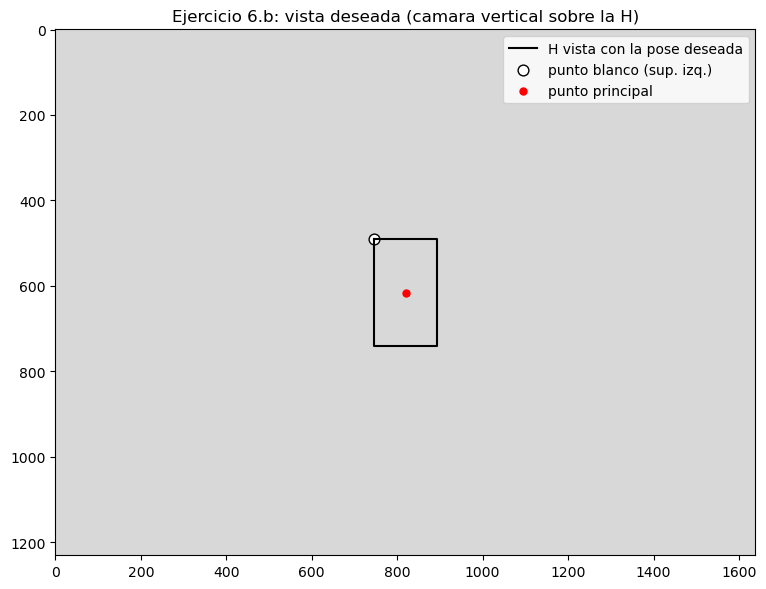

In [12]:
# b) Pose para ubicar al drone exactamente sobre la H, con la camara vertical y la H derecha
#
# Ejes de la camara expresados en el sistema de la H (U a la derecha, V hacia arriba, W = U x V hacia arriba):
#   i = +U (derecha de la imagen),  j = -V (abajo de la imagen),  k = -W (la camara mira hacia abajo)
Rd = np.array([[1.0,  0.0,  0.0],
               [0.0, -1.0,  0.0],
               [0.0,  0.0, -1.0]])

# Posicion actual de la camara en el sistema de la H:  X_cam = R X + t = 0  =>  C = -R^T t
C = -1.0 * alc.arroba(alc.traspuesta(R_dron), t_dron)

h = C[2]                                        # altura sobre la H (se decide mantener la actual)
td = np.array([0.0, 0.0, h])                    # el centro de la H queda sobre el eje optico
Rrel = alc.arroba(Rd, alc.traspuesta(R_dron))   # rotacion del sistema de camara actual al deseado

print("Posicion actual de la camara en el sistema de la H (m):", C)
print("\nPose deseada:")
print("Rd ="); print(Rd)
print("td (m) =", td)
print("\nRotacion relativa Rrel = Rd R^T:"); print(Rrel)
print("\nDesplazamiento horizontal necesario (dU, dV) en m: (%.3f, %.3f)" % (-C[0], -C[1]))
print("Coseno del angulo de inclinacion actual respecto de la vertical (-R33): %.4f" % (-R_dron[2, 2]))

# Vista que tendria la camara con la pose deseada: la H derecha y centrada en la imagen
uv_d = proyectar(Rd, td, K_dron, contorno)
blanco = proyectar(Rd, td, K_dron, obj_vecs[1:2])         # esquina superior izquierda de la H (punto blanco)
lienzo = np.ones((int(2 * K_dron[1, 2]), int(2 * K_dron[0, 2]), 3)) * 0.85

plt.figure(figsize=(8, 6))
plt.imshow(lienzo)
plt.plot(uv_d[:, 0], uv_d[:, 1], 'k-', label='H vista con la pose deseada')
plt.scatter(blanco[:, 0], blanco[:, 1], c='white', edgecolors='k', s=60, label='punto blanco (sup. izq.)')
plt.scatter([K_dron[0, 2]], [K_dron[1, 2]], c='red', s=25, label='punto principal')
plt.title('Ejercicio 6.b: vista deseada (camara vertical sobre la H)')
plt.legend()
plt.tight_layout()
plt.show()

**b) Pose deseada.** Para que el drone quede exactamente sobre la H con la cámara vertical y la letra derecha en la imagen (con el punto blanco, la esquina superior izquierda de la H, arriba a la izquierda), los ejes de la cámara expresados en el sistema de la H tienen que ser $\mathbf i=+U$ (derecha de la imagen), $\mathbf j=-V$ (abajo de la imagen) y $\mathbf k=-W$ (la cámara mira hacia el piso). Además el centro de la H debe estar sobre el eje óptico, es decir $X_{cam}(M_0)=(0,0,h)$. Entonces

$$R_d=\begin{pmatrix}1&0&0\\0&-1&0\\0&0&-1\end{pmatrix},\qquad t_d=\begin{pmatrix}0\\0\\h\end{pmatrix}$$

con $h$ la altura de la cámara sobre la H. El enunciado no fija $h$; tomamos la altura actual, $h=4.54$ m, de modo que solo hay que mover al drone horizontalmente y rotarlo. La figura muestra que con esa pose la H queda derecha y centrada sobre el punto principal. Con una altura menor la letra ocuparía una porción mayor de la imagen y $t_d$ cambia solamente en su tercera componente.

**Movimiento respecto de la pose actual.** La posición actual de la cámara en el sistema de la H es $C=-R^tt\approx(-1.04,\ -0.36,\ 4.54)$ m, de modo que el drone debe desplazarse $(\Delta U,\Delta V)\approx(1.04,\ 0.36)$ m sobre el plano de la H para ubicarse sobre su centro. La rotación que lleva el sistema de la cámara actual al deseado es $R_{rel}=R_dR^t$:

$$R_{rel}\approx\begin{pmatrix}-0.137&-0.909&0.393\\0.990&-0.107&0.097\\-0.047&0.402&0.914\end{pmatrix}$$

Esa rotación combina un giro de unos 98° alrededor del eje óptico, porque la H aparece de costado en la imagen actual, con una inclinación de unos 24° respecto de la vertical ($-R_{33}\approx0.914$ es el coseno de ese ángulo) que hay que corregir para que la cámara mire hacia abajo.

---